# Twenty trajectories per source

Notebook 01 established that mixed-T initial latent coordinates can order fitted final p-ratio in the extreme-low-data model. Most analyses below use only the node-optimized and stiffness-optimized mixed-T held-out trajectories; one matched panel compares the same low-T trajectories between the one- and 20-per-source encoders. The frozen models were trained on the complete paired low/mixed four-source data. The one-trajectory model is used only for latent organization; rollout diagnostics use the 20-per-source model.

The stiffness-optimized mini collection remains distinct from the historical Reid dataset. No p-ratio or strain enters training, loss, validation selection, or checkpoint choice.


In [1]:
%matplotlib inline
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import Normalize, LogNorm
from IPython.display import display

ROOT = Path.cwd().resolve()
while not (ROOT/'notebooks').exists():
    if ROOT.parent == ROOT: raise RuntimeError('Run inside the repository')
    ROOT = ROOT.parent
BASE = ROOT/'notebooks/results/all4_coverage_1000'
MIXED_ONLY = ROOT/'notebooks/results/mini_temperature1000_mixed_only'
MIXED_ONLY_PREFIX = MIXED_ONLY/'prefix_linear_fit'/'joint_mixed_only'
RUNS = {
    '1 per source': BASE/'all4_one_each_retry_v5_validation30',
    '20 per source': BASE/'all4_twenty_each_retry_v5_validation30',
}
SOURCES = ['node_low','node_mixed','stiffness_low','stiffness_mixed']
DISPLAY_SOURCES = ['node_mixed','stiffness_mixed']
LABELS = {'node_low':'node optimized · low-T','node_mixed':'node optimized · mixed-T','stiffness_low':'stiffness optimized · low-T','stiffness_mixed':'stiffness optimized · mixed-T'}
COLORS = {'node_low':'#2166ac','node_mixed':'#67a9cf','stiffness_low':'#b2182b','stiffness_mixed':'#ef8a62'}
ROLLOUT_MODE = 'autonomous_delta_mlp'
MARKERS = {'node_mixed':'o','stiffness_mixed':'^'}
plt.rcParams.update({'figure.dpi':115,'axes.spines.top':False,'axes.spines.right':False,'axes.grid':True,'grid.alpha':.18,'legend.frameon':False,'font.size':9.5})

manifest=json.loads((MIXED_ONLY/'data_manifest.json').read_text())
temperature_rows=[]
for source in DISPLAY_SOURCES:
    source_manifest=json.loads(Path(manifest['datasets'][source]['manifest_path']).read_text())
    for record in source_manifest['records']:
        temperature_rows.append({'source':source,'trajectory_id':int(record['source_index']),
                                 'temperature_K':float(record['temperature_K'])})
temperatures=pd.DataFrame(temperature_rows)
TEMP_NORM=LogNorm(vmin=temperatures.temperature_K.min(),vmax=temperatures.temperature_K.max())
TEMP_CMAP=plt.get_cmap('plasma')

data = {}
for name,path in RUNS.items():
    required = [path/'completed.json',path/'exposure.csv',path/'test/latents.csv',path/'test/per_network.csv',path/'test/per_step.csv',path/'auxiliary_linear_fit/per_network.csv',path/'auxiliary_linear_fit/summary.csv',path/'auxiliary_linear_fit/completed.json']
    missing = [str(p) for p in required if not p.exists()]
    if missing: raise FileNotFoundError('Missing frozen artifacts:\n'+'\n'.join(missing))
    item = {key: pd.read_csv(value) for key,value in {
        'exposure':path/'exposure.csv','latents':path/'test/latents.csv','network':path/'test/per_network.csv','step':path/'test/per_step.csv','linear_network':path/'auxiliary_linear_fit/per_network.csv','linear_summary':path/'auxiliary_linear_fit/summary.csv'}.items()}
    assert json.loads((path/'completed.json').read_text())['status']=='completed'
    assert json.loads((path/'auxiliary_linear_fit/completed.json').read_text())['status']=='completed'
    assert item['latents'].groupby(['source','trajectory_id']).size().eq(200).all()
    data[name]=item
print('Loaded two frozen seed-123 models; each is evaluated on the identical 320 held-out trajectories.')


Loaded two frozen seed-123 models; each is evaluated on the identical 320 held-out trajectories.


## Training data


In [2]:
rows=[]
for model,item in data.items():
    train=item['exposure'].query("split=='train' and source in @DISPLAY_SOURCES")
    for source,g in train.groupby('source'):
        rows.append({'model':model,'source':LABELS[source],'trajectories':len(g),'unique IDs':g.trajectory_id.nunique(),'frames':int(g.frames.sum()),'temperatures (K)':', '.join(map(str,sorted(g.temperature.unique())))})
display(pd.DataFrame(rows))
print('Shown: mixed-T half only. The frozen models also saw the paired low-T trajectories of the same structures: complete exposure is 4 trajectories / 2 unique structures versus 80 trajectories / 40 unique structures.')


,model,source,trajectories,unique IDs,frames,temperatures (K)
0,1 per source,node optimized · mixed-T,1,1,200,0.1
1,1 per source,stiffness optimized · mixed-T,1,1,200,0.1
2,20 per source,node optimized · mixed-T,20,20,4000,"0.1, 1.0, 5.0, 10.0, 20.0"
3,20 per source,stiffness optimized · mixed-T,20,20,4000,"0.1, 1.0, 5.0, 10.0, 20.0"


Shown: mixed-T half only. The frozen models also saw the paired low-T trajectories of the same structures: complete exposure is 4 trajectories / 2 unique structures versus 80 trajectories / 40 unique structures.


## Initial state

Final response uses the physical frame-199 endpoint at low temperature and normalized boundary-strain OLS over frames 30–199 at mixed temperature. Correlations are computed separately within each source.


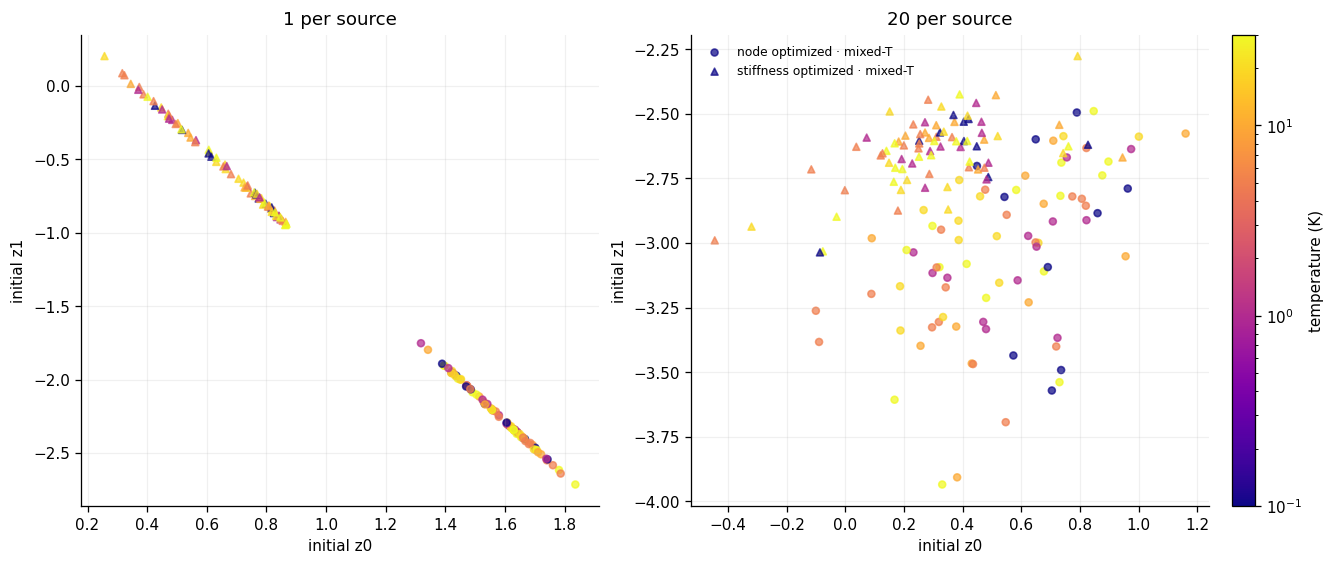

In [3]:
def descriptors(item):
    low=(item['network'].query("mode==@ROLLOUT_MODE and frame==199 and source in ['node_low','stiffness_low']")
         [['source','trajectory_id','true_p_ratio']].rename(columns={'true_p_ratio':'final_p_ratio'}))
    mixed=(item['linear_network'].query("mode==@ROLLOUT_MODE")
           [['source','trajectory_id','linear_true_p']].rename(columns={'linear_true_p':'final_p_ratio'}))
    initial=item['latents'].query('frame==0')[['source','trajectory_id','z0','z1']]
    result=initial.merge(pd.concat([low,mixed]),on=['source','trajectory_id'],validate='one_to_one')
    assert len(result)==320 and result.final_p_ratio.notna().all()
    return result

desc={name:descriptors(item) for name,item in data.items()}
fig,axes=plt.subplots(1,2,figsize=(11.5,4.8),constrained_layout=True)
for ax,(model,values) in zip(axes,desc.items()):
    for source in DISPLAY_SOURCES:
        g=values.query('source==@source').merge(temperatures,on=['source','trajectory_id'],validate='one_to_one')
        ax.scatter(g.z0,g.z1,c=g.temperature_K,cmap=TEMP_CMAP,norm=TEMP_NORM,
                   marker=MARKERS[source],s=19,alpha=.72,label=LABELS[source])
    ax.set(title=model,xlabel='initial z0',ylabel='initial z1')
axes[1].legend(fontsize=7.7,loc='best')
fig.colorbar(plt.cm.ScalarMappable(norm=TEMP_NORM,cmap=TEMP_CMAP),ax=axes,label='temperature (K)',fraction=.025,pad=.02)
plt.show()


## Latent trajectories

The raw path is shown faintly. The clearer line is a centered three-frame vector average in time, with frames 0 and 199 kept unchanged. This suppresses single-frame thermal jitter while preserving the actual temporal ordering and endpoints; unlike the previous quadratic fit, it cannot force the whole trajectory into an artificial parabola. This smoothing is used only for this visualization.


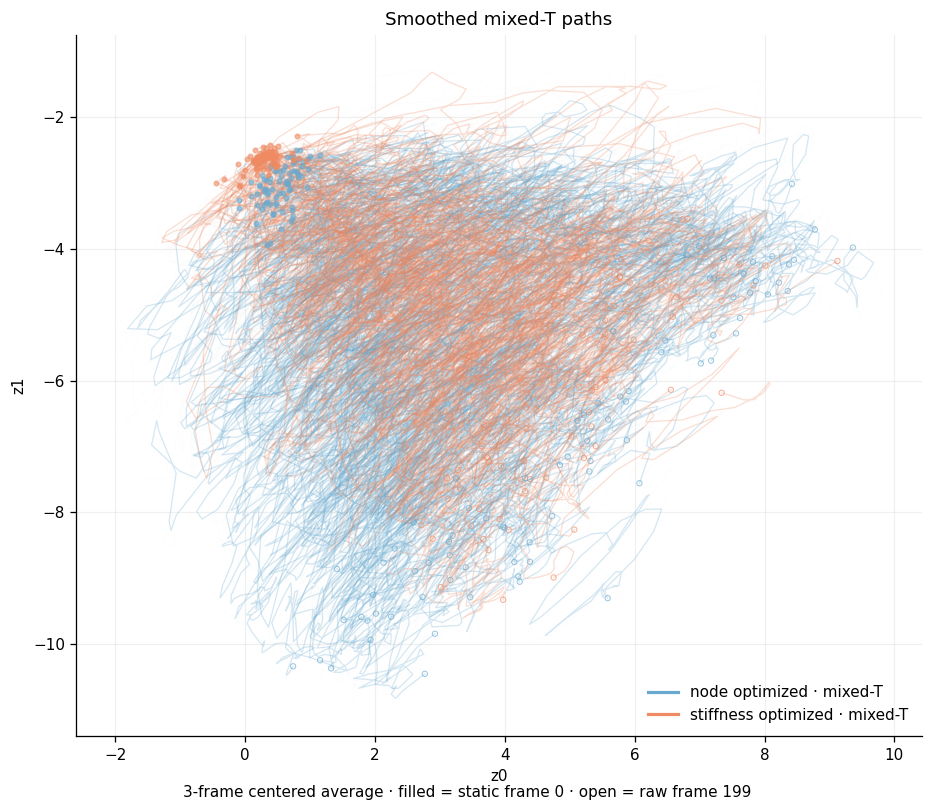

In [4]:
fig,ax=plt.subplots(figsize=(8.0,6.8),constrained_layout=True)
trajectory_latents=data['20 per source']['latents'].sort_values(['source','trajectory_id','frame'])
for source in DISPLAY_SOURCES:
    source_paths=trajectory_latents.query('source==@source')
    for _,path in source_paths.groupby('trajectory_id'):
        path=path.sort_values('frame')
        latent=path[['z0','z1']].to_numpy()
        trend=latent.copy()
        trend[1:-1]=(latent[:-2]+latent[1:-1]+latent[2:])/3
        ax.plot(latent[:,0],latent[:,1],color=COLORS[source],lw=.35,alpha=.025)
        ax.plot(trend[:,0],trend[:,1],color=COLORS[source],lw=.8,alpha=.27)
        ax.scatter(path.z0.iloc[0],path.z1.iloc[0],s=8,color=COLORS[source],alpha=.55,zorder=3)
        ax.scatter(trend[-1,0],trend[-1,1],s=11,facecolors='none',edgecolors=COLORS[source],linewidth=.65,alpha=.65,zorder=3)
    ax.plot([],[],color=COLORS[source],lw=2,label=LABELS[source])
ax.set(title='Smoothed mixed-T paths',xlabel='z0',ylabel='z1')
ax.legend()
fig.text(.5,-.01,'3-frame centered average · filled = static frame 0 · open = raw frame 199',ha='center')
plt.show()


## Same low-T networks

The same 10 held-out physical trajectories are shown together in each encoder's raw z0-z1 coordinates, without centering, scaling, rotation or alignment. Trained-on-1 paths remain orange; trained-on-20 paths are coloured by final p-ratio. Line style denotes node- or stiffness-optimized data. Because the two latent coordinate systems were learned independently, their absolute offsets and orientations do not have a shared physical meaning.


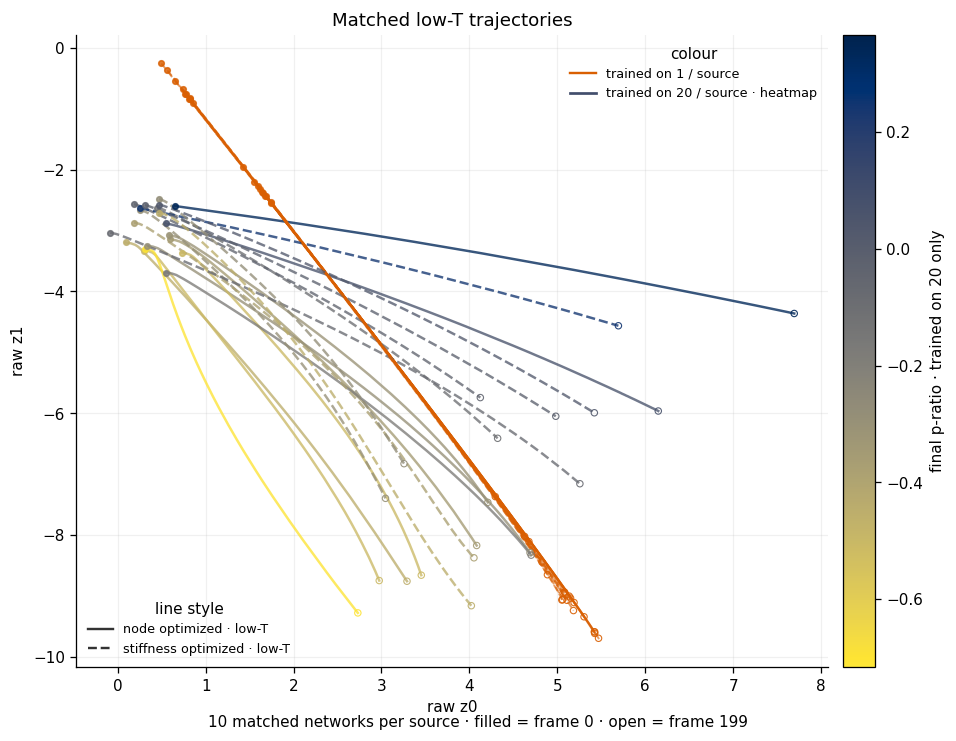

In [5]:
from matplotlib.lines import Line2D

LOW_SOURCES=['node_low','stiffness_low']
MATCHED_IDS=np.linspace(40,119,10,dtype=int).tolist()
MODEL_STYLE={
    '1 per source': {'color':'#d95f02','linewidth':1.20,'alpha':.62},
    '20 per source': {'linewidth':1.55,'alpha':.78},
}
SOURCE_STYLE={'node_low':'-','stiffness_low':'--'}
matched_final=data['20 per source']['latents'].query(
    'source in @LOW_SOURCES and 40<=trajectory_id<=119 and frame==199').p_ratio
MATCHED_NORM=Normalize(vmin=matched_final.quantile(.02),vmax=matched_final.quantile(.98))
MATCHED_CMAP=plt.get_cmap('cividis_r')
fig,ax=plt.subplots(figsize=(8.2,6.2),constrained_layout=True)
for source in LOW_SOURCES:
    for trajectory_id in MATCHED_IDS:
        for model in ['1 per source','20 per source']:
            path=(data[model]['latents'].query('source==@source and trajectory_id==@trajectory_id')
                  .sort_values('frame'))
            assert path.frame.tolist()==list(range(200))
            z=path[['z0','z1']].to_numpy()
            style=MODEL_STYLE[model]
            color=(style['color'] if model=='1 per source'
                   else MATCHED_CMAP(MATCHED_NORM(float(path.p_ratio.iloc[-1]))))
            ax.plot(z[:,0],z[:,1],linestyle=SOURCE_STYLE[source],lw=style['linewidth'],
                    color=color,alpha=style['alpha'])
            ax.scatter(z[0,0],z[0,1],s=12,color=color,alpha=.82,zorder=3)
            ax.scatter(z[-1,0],z[-1,1],s=16,facecolors='none',
                       edgecolors=color,linewidth=.7,alpha=.9,zorder=3)
ax.set(title='Matched low-T trajectories',xlabel='raw z0',ylabel='raw z1')

model_handles=[
    Line2D([0],[0],color=MODEL_STYLE['1 per source']['color'],lw=1.5,label='trained on 1 / source'),
    Line2D([0],[0],color=MATCHED_CMAP(.75),lw=1.7,label='trained on 20 / source · heatmap'),
]
source_handles=[Line2D([0],[0],color='#333333',lw=1.5,ls=SOURCE_STYLE[source],
                       label=LABELS[source]) for source in LOW_SOURCES]
legend_training=ax.legend(handles=model_handles,title='colour',fontsize=8,loc='upper right')
ax.add_artist(legend_training)
ax.legend(handles=source_handles,title='line style',fontsize=8,loc='lower left')
fig.colorbar(plt.cm.ScalarMappable(norm=MATCHED_NORM,cmap=MATCHED_CMAP),
             ax=ax,label='final p-ratio · trained on 20 only',fraction=.045,pad=.02)
fig.text(.5,-.01,f'{len(MATCHED_IDS)} matched networks per source · filled = frame 0 · open = frame 199',ha='center')
plt.show()


## Shared response across network families

This is a post-hoc diagnostic of the frozen 20-network encoder, not an input, loss or checkpoint-selection metric. The strongest test transfers a linear p-ratio relation fitted on one optimization family directly to the other family.


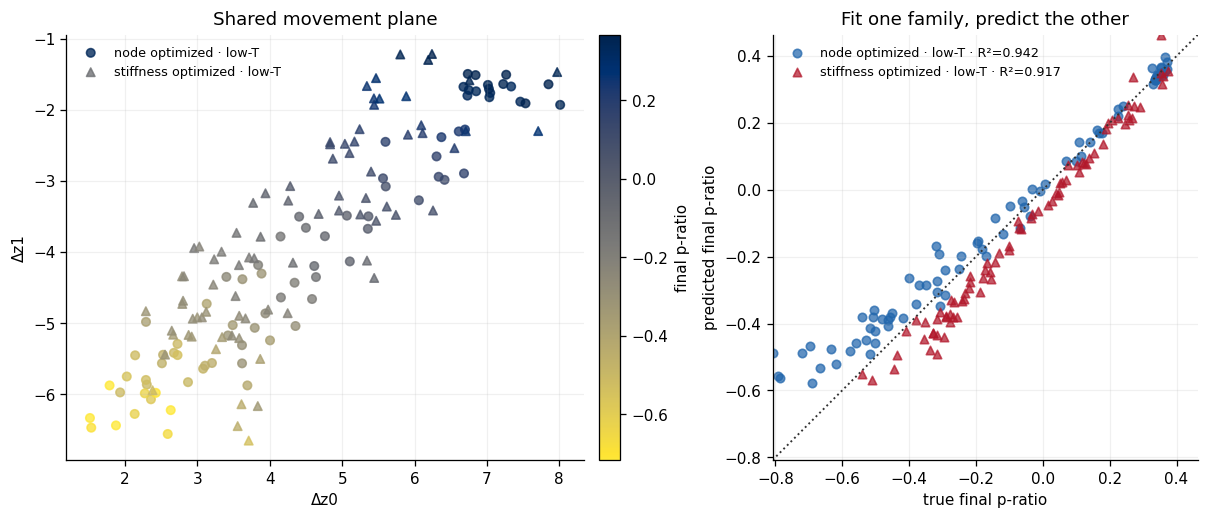

,test,R²,valid/total
0,one shared fit on both families,0.971,160/160
1,fit stiffness optimized · low-T → test node op...,0.942,80/80
2,fit node optimized · low-T → test stiffness op...,0.917,80/80


In [6]:
shared_rows=[]
latent=data['20 per source']['latents']
for source in LOW_SOURCES:
    initial=latent.query('source==@source and 40<=trajectory_id<=119 and frame==0').set_index('trajectory_id').sort_index()
    final=latent.query('source==@source and 40<=trajectory_id<=119 and frame==199').set_index('trajectory_id').sort_index()
    delta=final[['z0','z1']].to_numpy()-initial[['z0','z1']].to_numpy()
    for trajectory_id,(change,p_ratio) in zip(final.index,zip(delta,final.p_ratio)):
        shared_rows.append({'source':source,'trajectory_id':trajectory_id,
                            'Δz0':change[0],'Δz1':change[1],'final p-ratio':p_ratio})
shared=pd.DataFrame(shared_rows)
response_norm=Normalize(vmin=shared['final p-ratio'].quantile(.02),
                        vmax=shared['final p-ratio'].quantile(.98))
response_cmap=plt.get_cmap('cividis_r')

def fit_linear(frame):
    design=np.column_stack([np.ones(len(frame)),frame[['Δz0','Δz1']].to_numpy()])
    return np.linalg.lstsq(design,frame['final p-ratio'].to_numpy(),rcond=None)[0]

def predict_linear(frame,coef):
    design=np.column_stack([np.ones(len(frame)),frame[['Δz0','Δz1']].to_numpy()])
    return design@coef

def score_r2(true,predicted):
    return 1-np.square(true-predicted).sum()/np.square(true-true.mean()).sum()

pooled_coef=fit_linear(shared)
pooled_prediction=predict_linear(shared,pooled_coef)
pooled_r2=score_r2(shared['final p-ratio'].to_numpy(),pooled_prediction)

transfer=[]
for train_source,test_source in [('node_low','stiffness_low'),('stiffness_low','node_low')]:
    train=shared.query('source==@train_source')
    test=shared.query('source==@test_source').copy()
    test['predicted p-ratio']=predict_linear(test,fit_linear(train))
    transfer.append(test.assign(trained_on=train_source))
transfer=pd.concat(transfer,ignore_index=True)

fig,axes=plt.subplots(1,2,figsize=(10.8,4.4),constrained_layout=True)
for source,marker in [('node_low','o'),('stiffness_low','^')]:
    values=shared.query('source==@source')
    axes[0].scatter(values['Δz0'],values['Δz1'],c=values['final p-ratio'],
                    cmap=response_cmap,norm=response_norm,marker=marker,s=28,alpha=.78,
                    label=LABELS[source])
axes[0].set(title='Shared movement plane',xlabel='Δz0',ylabel='Δz1')
axes[0].legend(fontsize=8)
fig.colorbar(plt.cm.ScalarMappable(norm=response_norm,cmap=response_cmap),
             ax=axes[0],label='final p-ratio',fraction=.05,pad=.03)

transfer_scores=[]
for source,marker in [('node_low','o'),('stiffness_low','^')]:
    values=transfer.query('source==@source')
    score=score_r2(values['final p-ratio'].to_numpy(),values['predicted p-ratio'].to_numpy())
    transfer_scores.append({'test':f"fit {LABELS[values.trained_on.iloc[0]]} → test {LABELS[source]}",
                            'R²':score,'valid/total':'80/80'})
    axes[1].scatter(values['final p-ratio'],values['predicted p-ratio'],marker=marker,s=28,
                    color=COLORS[source],alpha=.72,label=f"{LABELS[source]} · R²={score:.3f}")
limits=[min(transfer['final p-ratio'].min(),transfer['predicted p-ratio'].min()),
        max(transfer['final p-ratio'].max(),transfer['predicted p-ratio'].max())]
axes[1].plot(limits,limits,ls=':',color='#333333',lw=1.2)
axes[1].set(title='Fit one family, predict the other',xlabel='true final p-ratio',
            ylabel='predicted final p-ratio',xlim=limits,ylim=limits,aspect='equal')
axes[1].legend(fontsize=8)
plt.show()

shared_summary=pd.DataFrame([{'test':'one shared fit on both families','R²':pooled_r2,'valid/total':'160/160'},
                             *transfer_scores])
display(shared_summary.round({'R²':3}))


## Early latent and physical response

Six negative-p networks per family are shown over frames 0–20. The left column is the latent path after subtracting each trajectory's own frame-0 latent position. The middle column is the measured physical deformation. The right column compares the cumulative latent slope `Δz1/Δz0` with `p(t) = -ΔLy/ΔLx`. The shape plots below show both the direct transverse response and the combinations that include the imposed x-compression. Every curve in those shape panels is divided by its own frame-20 value; this removes magnitude and compares temporal shape only. The later centered-difference scatter uses raw, unnormalized changes.


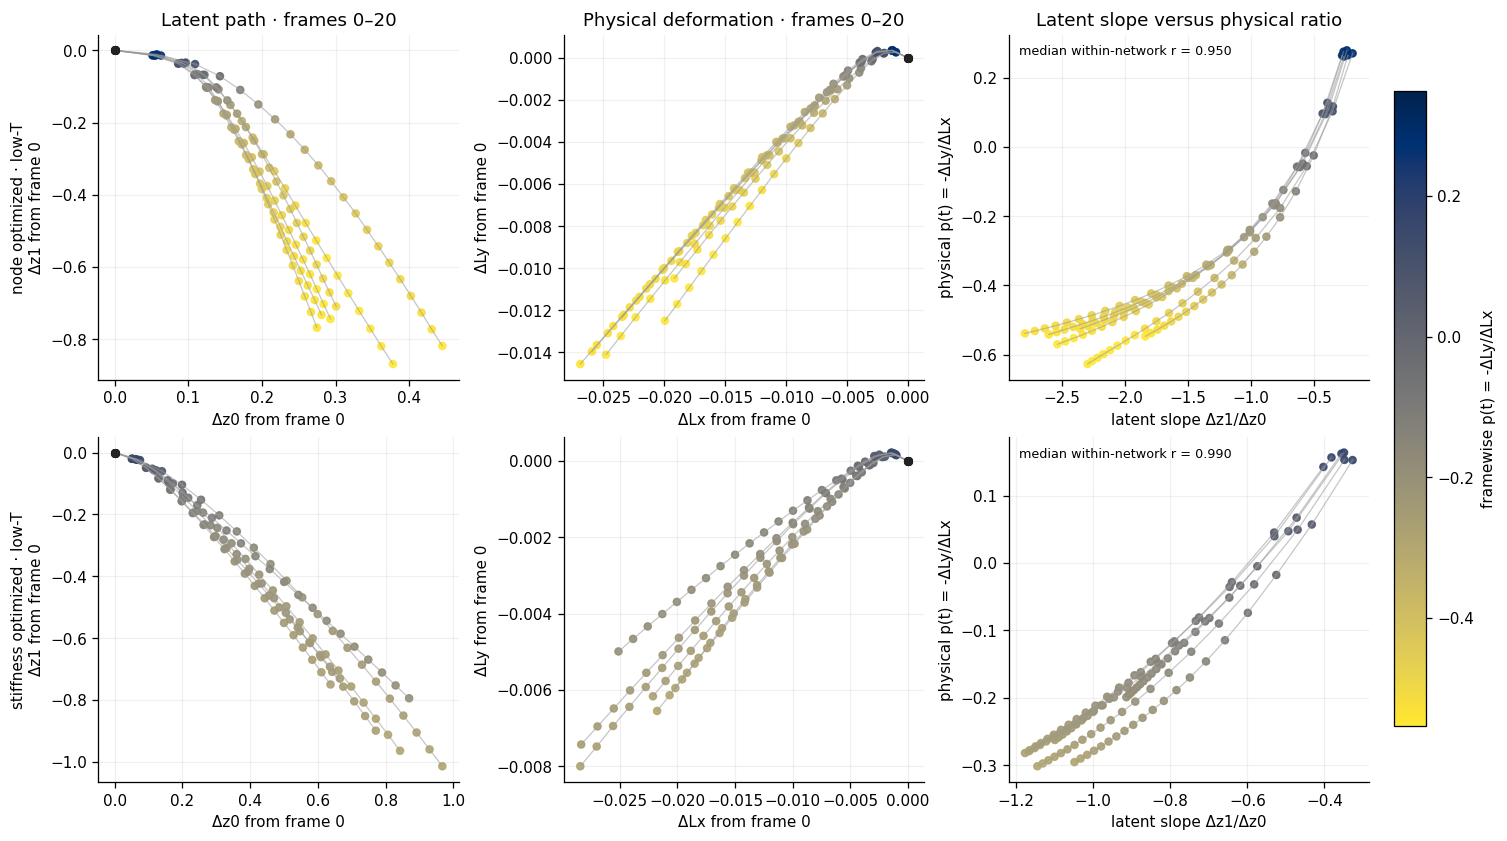

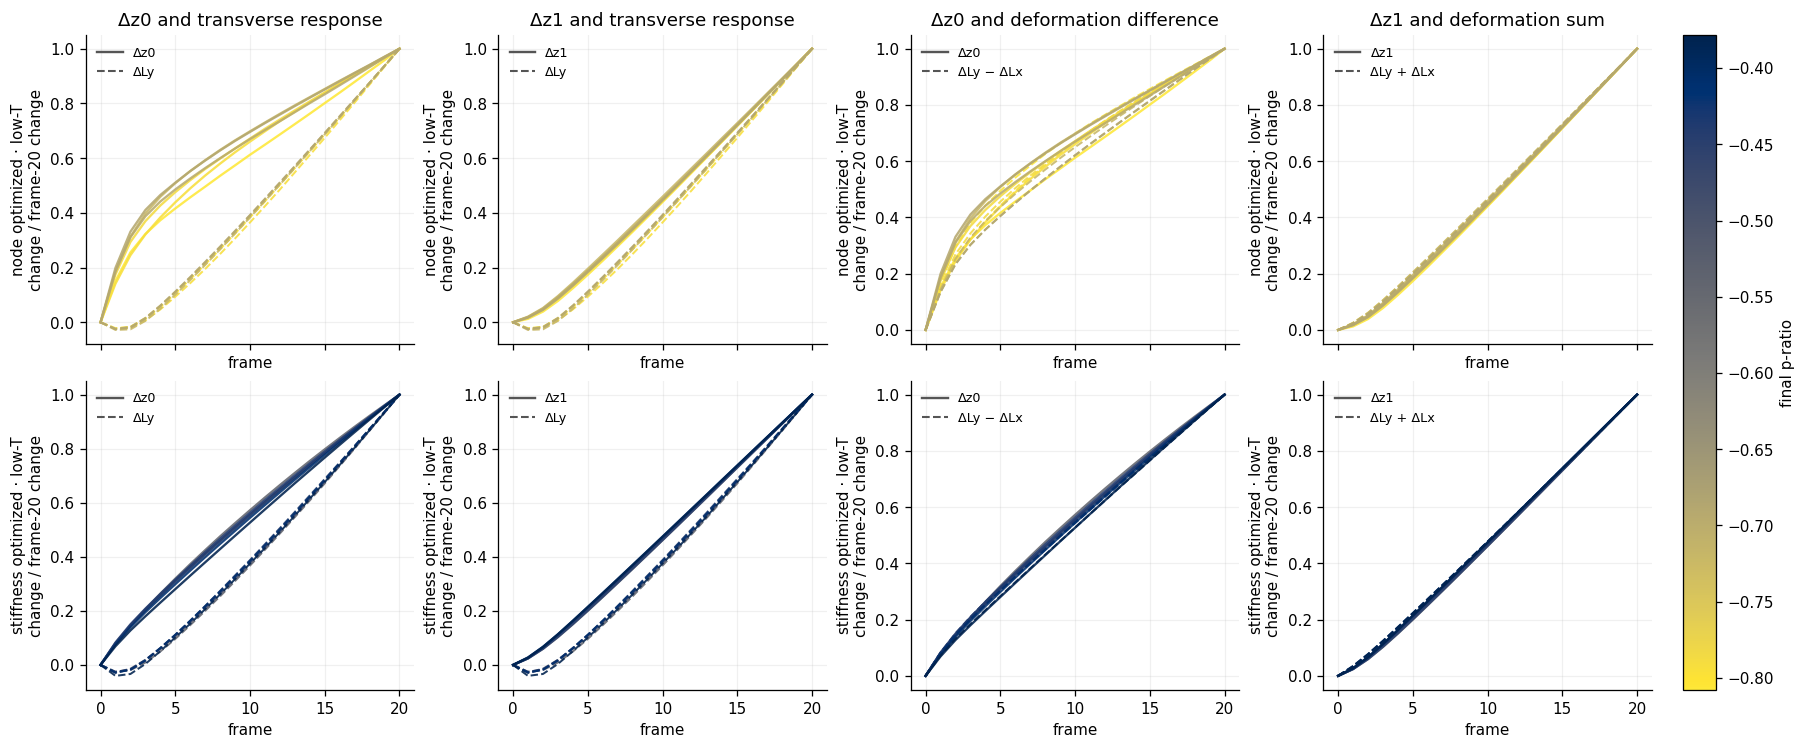

All four columns divide each curve by its own frame-20 value; they compare shape, not magnitude.


,source,"median |r|(Δz0, ΔLy)","median |r|(Δz1, ΔLy)","median |r|(Δz0, ΔLy−ΔLx)","median |r|(Δz1, ΔLy+ΔLx)","median r(Δz1/Δz0, p(t))",valid/total
0,node optimized · low-T,0.9939,0.9992,0.9999,1.0,0.9739,80/80
1,stiffness optimized · low-T,0.9965,0.9986,0.9999,1.0,0.9910,80/80


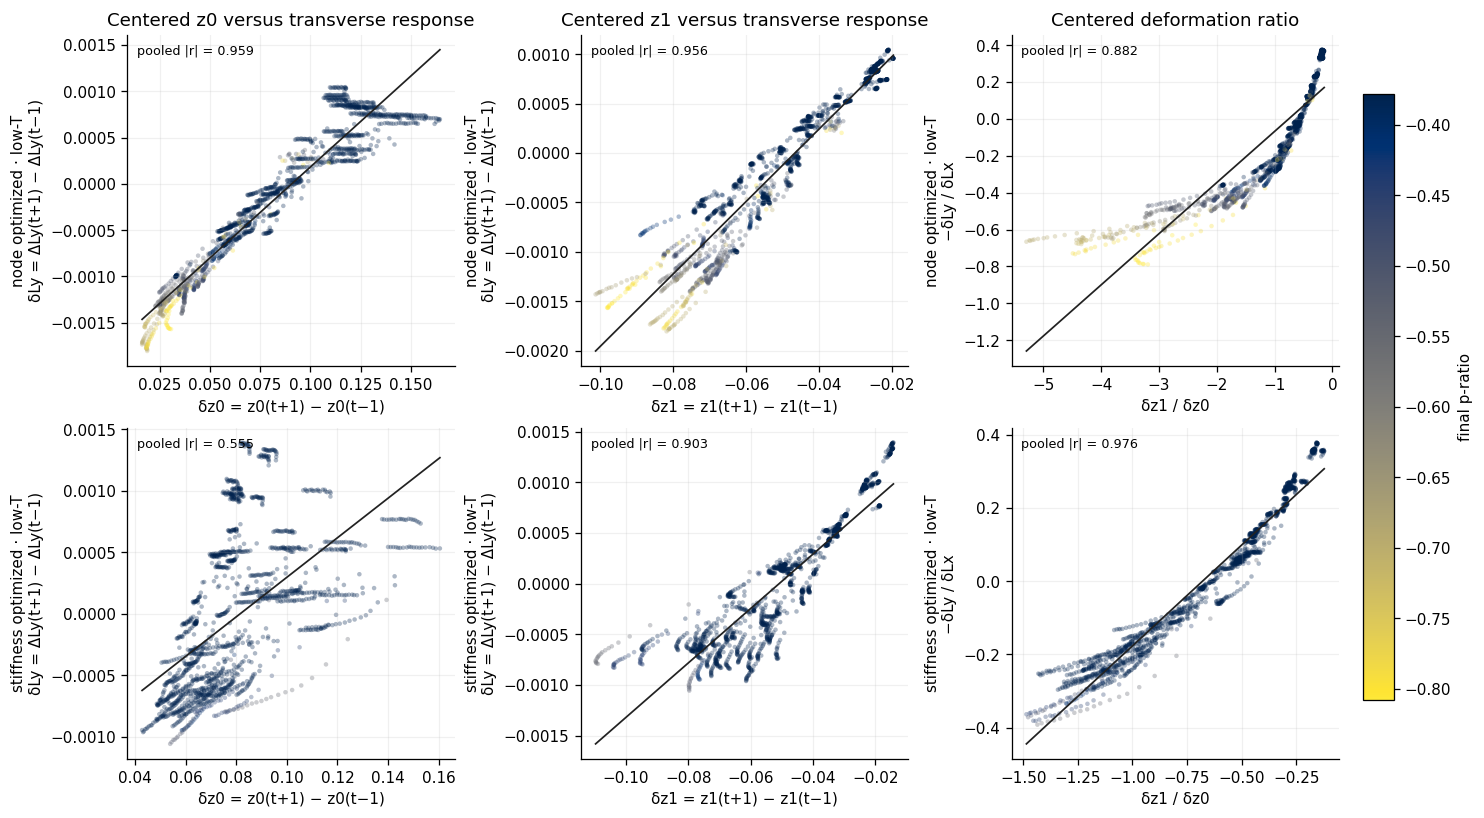

Centered change means value(t+1) − value(t−1), evaluated at frames 1–19.


,source,within |r|: δz0 vs δLy,pooled |r|: δz0 vs δLy,within |r|: δz1 vs δLy,pooled |r|: δz1 vs δLy,within |r|: ratio,pooled |r|: ratio,valid/total
0,node optimized · low-T,0.99,0.959,0.988,0.956,0.963,0.882,80/80
1,stiffness optimized · low-T,0.94,0.555,0.981,0.903,0.972,0.976,80/80


In [7]:
early_latent=data['20 per source']['latents']
selected_negative={}
for source in LOW_SOURCES:
    endpoint=(early_latent.query('source==@source and frame==199 and 40<=trajectory_id<=119')
              [['trajectory_id','p_ratio']].sort_values('p_ratio'))
    selected_negative[source]=endpoint.query('p_ratio<0').head(6).trajectory_id.tolist()

selected_ids=[trajectory_id for ids in selected_negative.values() for trajectory_id in ids]
early_p=early_latent.query(
    'source in @LOW_SOURCES and trajectory_id in @selected_ids and 1<=frame<=20').p_ratio
EARLY_P_NORM=Normalize(vmin=early_p.quantile(.02),vmax=early_p.quantile(.98))
EARLY_P_CMAP=plt.get_cmap('cividis_r')

shape_by_source={}
fig,axes=plt.subplots(2,3,figsize=(13.0,7.2),constrained_layout=True)
for row,source in enumerate(LOW_SOURCES):
    ratio_correlations=[]
    normalized_z0=[]; normalized_z1=[]; normalized_y=[]
    normalized_difference=[]; normalized_sum=[]; final_p_values=[]
    for trajectory_id in selected_negative[source]:
        path=(early_latent.query('source==@source and trajectory_id==@trajectory_id')
              .sort_values('frame'))
        early=path.query('frame<=20').copy()
        dz=early[['z0','z1']].to_numpy()-early[['z0','z1']].iloc[0].to_numpy()
        frame_p=early.p_ratio.to_numpy()
        axes[row,0].plot(dz[:,0],dz[:,1],color='#999999',lw=.8,alpha=.55)
        axes[row,0].scatter(dz[1:,0],dz[1:,1],c=frame_p[1:],cmap=EARLY_P_CMAP,
                            norm=EARLY_P_NORM,s=19,alpha=.9)
        axes[row,0].scatter([0],[0],s=22,color='#222222',zorder=4)

        physical=early[['x_deformation','y_deformation']].to_numpy()
        axes[row,1].plot(physical[:,0],physical[:,1],color='#999999',lw=.8,alpha=.55)
        axes[row,1].scatter(physical[1:,0],physical[1:,1],c=frame_p[1:],cmap=EARLY_P_CMAP,
                            norm=EARLY_P_NORM,s=19,alpha=.9)
        axes[row,1].scatter([0],[0],s=22,color='#222222',zorder=4)

        latent_slope=dz[1:,1]/dz[1:,0]
        axes[row,2].plot(latent_slope,frame_p[1:],color='#999999',lw=.8,alpha=.55)
        axes[row,2].scatter(latent_slope,frame_p[1:],c=frame_p[1:],cmap=EARLY_P_CMAP,
                            norm=EARLY_P_NORM,s=19,alpha=.9)
        ratio_correlations.append(np.corrcoef(latent_slope,frame_p[1:])[0,1])
        deformation_difference=physical[:,1]-physical[:,0]
        deformation_sum=physical[:,0]+physical[:,1]
        normalized_z0.append(dz[:,0]/dz[-1,0]); normalized_z1.append(dz[:,1]/dz[-1,1])
        normalized_y.append(physical[:,1]/physical[-1,1])
        normalized_difference.append(deformation_difference/deformation_difference[-1])
        normalized_sum.append(deformation_sum/deformation_sum[-1])
        final_p_values.append(float(path.query('frame==199').p_ratio.iloc[0]))

    median_corr=np.median(ratio_correlations)
    shape_by_source[source]={
        'z0':np.asarray(normalized_z0),'z1':np.asarray(normalized_z1),
        'y':np.asarray(normalized_y),'difference':np.asarray(normalized_difference),
        'sum':np.asarray(normalized_sum),
        'final_p':np.asarray(final_p_values),
    }
    axes[row,0].set(ylabel=f"{LABELS[source]}\nΔz1 from frame 0",xlabel='Δz0 from frame 0')
    axes[row,1].set(xlabel='ΔLx from frame 0',ylabel='ΔLy from frame 0')
    axes[row,2].set(xlabel='latent slope Δz1/Δz0',ylabel='physical p(t) = -ΔLy/ΔLx')
    axes[row,2].text(.03,.97,f"median within-network r = {median_corr:.3f}",
                     transform=axes[row,2].transAxes,ha='left',va='top',fontsize=8)

axes[0,0].set_title('Latent path · frames 0–20')
axes[0,1].set_title('Physical deformation · frames 0–20')
axes[0,2].set_title('Latent slope versus physical ratio')
fig.colorbar(plt.cm.ScalarMappable(norm=EARLY_P_NORM,cmap=EARLY_P_CMAP),
             ax=axes,label='framewise p(t) = -ΔLy/ΔLx',fraction=.025,pad=.02)
plt.show()

all_selected_final_p=np.concatenate([shape_by_source[source]['final_p'] for source in LOW_SOURCES])
SHAPE_NORM=Normalize(vmin=all_selected_final_p.min(),vmax=all_selected_final_p.max())
fig,shape_axes=plt.subplots(2,4,figsize=(15.6,6.4),sharex=True,constrained_layout=True)
frames=np.arange(21)
for row,source in enumerate(LOW_SOURCES):
    shapes=shape_by_source[source]
    for column,(latent_key,physical_key,latent_label,physical_label) in enumerate([
        ('z0','y','Δz0','ΔLy'),('z1','y','Δz1','ΔLy'),
        ('z0','difference','Δz0','ΔLy − ΔLx'),
        ('z1','sum','Δz1','ΔLy + ΔLx')]):
        ax=shape_axes[row,column]
        latent_values=shapes[latent_key]; physical_values=shapes[physical_key]
        for latent_curve,physical_curve,final_p in zip(latent_values,physical_values,shapes['final_p']):
            color=EARLY_P_CMAP(SHAPE_NORM(final_p))
            ax.plot(frames,latent_curve,color=color,lw=1.45,alpha=.88)
            ax.plot(frames,physical_curve,color=color,lw=1.25,ls='--',alpha=.88)
        ax.set(xlabel='frame',ylabel=f"{LABELS[source]}\nchange / frame-20 change")
        ax.plot([],[],color='#555555',lw=1.5,label=latent_label)
        ax.plot([],[],color='#555555',lw=1.3,ls='--',label=physical_label)
        ax.legend(fontsize=8)
shape_axes[0,0].set_title('Δz0 and transverse response')
shape_axes[0,1].set_title('Δz1 and transverse response')
shape_axes[0,2].set_title('Δz0 and deformation difference')
shape_axes[0,3].set_title('Δz1 and deformation sum')
fig.colorbar(plt.cm.ScalarMappable(norm=SHAPE_NORM,cmap=EARLY_P_CMAP),
             ax=shape_axes,label='final p-ratio',fraction=.025,pad=.02)
plt.show()
print('All four columns divide each curve by its own frame-20 value; they compare shape, not magnitude.')

match_rows=[]
for source in LOW_SOURCES:
    z0_y_r=[]; z1_y_r=[]; z0_difference_r=[]; z1_sum_r=[]; ratio_r=[]
    source_paths=early_latent.query('source==@source and 40<=trajectory_id<=119')
    for _,path in source_paths.groupby('trajectory_id'):
        early=path.sort_values('frame').query('frame<=20')
        dz=early[['z0','z1']].to_numpy()-early[['z0','z1']].iloc[0].to_numpy()
        dx=early.x_deformation.to_numpy(); dy=early.y_deformation.to_numpy()
        z0_y_r.append(abs(np.corrcoef(dz[1:,0],dy[1:])[0,1]))
        z1_y_r.append(abs(np.corrcoef(dz[1:,1],dy[1:])[0,1]))
        z0_difference_r.append(abs(np.corrcoef(dz[1:,0],(dy-dx)[1:])[0,1]))
        z1_sum_r.append(abs(np.corrcoef(dz[1:,1],(dy+dx)[1:])[0,1]))
        ratio_r.append(np.corrcoef(dz[1:,1]/dz[1:,0],-dy[1:]/dx[1:])[0,1])
    match_rows.append({'source':LABELS[source],
                       'median |r|(Δz0, ΔLy)':np.median(z0_y_r),
                       'median |r|(Δz1, ΔLy)':np.median(z1_y_r),
                       'median |r|(Δz0, ΔLy−ΔLx)':np.median(z0_difference_r),
                       'median |r|(Δz1, ΔLy+ΔLx)':np.median(z1_sum_r),
                       'median r(Δz1/Δz0, p(t))':np.median(ratio_r),
                       'valid/total':'80/80'})
display(pd.DataFrame(match_rows).round(4))

centered_rows=[]
centered_summary=[]
for source in LOW_SOURCES:
    source_paths=early_latent.query('source==@source and 40<=trajectory_id<=119')
    within={'z0':[],'z1':[],'ratio':[]}
    for trajectory_id,path in source_paths.groupby('trajectory_id'):
        path=path.sort_values('frame').reset_index(drop=True)
        endpoint_p=float(path.loc[path.frame.eq(199),'p_ratio'].iloc[0])
        trajectory_rows=[]
        for frame in range(1,20):
            dz0=float(path.z0.iloc[frame+1]-path.z0.iloc[frame-1])
            dz1=float(path.z1.iloc[frame+1]-path.z1.iloc[frame-1])
            dx=float(path.x_deformation.iloc[frame+1]-path.x_deformation.iloc[frame-1])
            dy=float(path.y_deformation.iloc[frame+1]-path.y_deformation.iloc[frame-1])
            trajectory_rows.append({'source':source,'trajectory_id':trajectory_id,'frame':frame,
                                    'latent z0':dz0,'latent z1':dz1,'physical y':dy,
                                    'latent ratio':dz1/dz0,'physical ratio':-dy/dx,
                                    'final p-ratio':endpoint_p})
        trajectory_table=pd.DataFrame(trajectory_rows)
        centered_rows.extend(trajectory_rows)
        within['z0'].append(abs(trajectory_table['latent z0'].corr(trajectory_table['physical y'])))
        within['z1'].append(abs(trajectory_table['latent z1'].corr(trajectory_table['physical y'])))
        within['ratio'].append(abs(trajectory_table['latent ratio'].corr(trajectory_table['physical ratio'])))
    source_centered=pd.DataFrame([row for row in centered_rows if row['source']==source])
    centered_summary.append({
        'source':LABELS[source],
        'within |r|: δz0 vs δLy':np.median(within['z0']),
        'pooled |r|: δz0 vs δLy':abs(source_centered['latent z0'].corr(source_centered['physical y'])),
        'within |r|: δz1 vs δLy':np.median(within['z1']),
        'pooled |r|: δz1 vs δLy':abs(source_centered['latent z1'].corr(source_centered['physical y'])),
        'within |r|: ratio':np.median(within['ratio']),
        'pooled |r|: ratio':abs(source_centered['latent ratio'].corr(source_centered['physical ratio'])),
        'valid/total':'80/80',
    })

centered=pd.DataFrame(centered_rows)
fig,centered_axes=plt.subplots(2,3,figsize=(12.8,7.0),constrained_layout=True)
for row,source in enumerate(LOW_SOURCES):
    values=centered.query('source==@source')
    for column,(latent_key,physical_key,title,xlabel,ylabel) in enumerate([
        ('latent z0','physical y','Centered z0 versus transverse response',
         'δz0 = z0(t+1) − z0(t−1)','δLy = ΔLy(t+1) − ΔLy(t−1)'),
        ('latent z1','physical y','Centered z1 versus transverse response',
         'δz1 = z1(t+1) − z1(t−1)','δLy = ΔLy(t+1) − ΔLy(t−1)'),
        ('latent ratio','physical ratio','Centered deformation ratio',
         'δz1 / δz0','−δLy / δLx')]):
        ax=centered_axes[row,column]
        ax.scatter(values[latent_key],values[physical_key],c=values['final p-ratio'],
                   cmap=EARLY_P_CMAP,norm=SHAPE_NORM,s=8,alpha=.32,lw=0)
        coefficients=np.polyfit(values[latent_key],values[physical_key],1)
        xx=np.linspace(values[latent_key].min(),values[latent_key].max(),100)
        ax.plot(xx,np.polyval(coefficients,xx),color='#222222',lw=1.1)
        pooled_r=abs(values[latent_key].corr(values[physical_key]))
        ax.text(.03,.97,f'pooled |r| = {pooled_r:.3f}',transform=ax.transAxes,
                ha='left',va='top',fontsize=8)
        ax.set(xlabel=xlabel,ylabel=f"{LABELS[source]}\n{ylabel}")
        if row==0: ax.set_title(title)
fig.colorbar(plt.cm.ScalarMappable(norm=SHAPE_NORM,cmap=EARLY_P_CMAP),
             ax=centered_axes,label='final p-ratio',fraction=.025,pad=.02)
plt.show()
print('Centered change means value(t+1) − value(t−1), evaluated at frames 1–19.')
display(pd.DataFrame(centered_summary).round(3))


In [8]:
corr=[]
for model,values in desc.items():
    for source in DISPLAY_SOURCES:
        g=values.query('source==@source')
        for latent in ['z0','z1']:
            corr.append({'training':model,'source':LABELS[source],'latent':f'initial {latent}','Pearson r':g[latent].corr(g.final_p_ratio),'Spearman ρ':g[latent].corr(g.final_p_ratio,method='spearman'),'valid/total':'80/80'})
correlations=pd.DataFrame(corr)
display(correlations.round({'Pearson r':3,'Spearman ρ':3}))


,training,source,latent,Pearson r,Spearman ρ,valid/total
0,1 per source,node optimized · mixed-T,initial z0,-0.878,-0.874,80/80
1,1 per source,node optimized · mixed-T,initial z1,0.882,0.876,80/80
2,1 per source,stiffness optimized · mixed-T,initial z0,-0.764,-0.767,80/80
3,1 per source,stiffness optimized · mixed-T,initial z1,0.754,0.759,80/80
4,20 per source,node optimized · mixed-T,initial z0,0.523,0.526,80/80
5,20 per source,node optimized · mixed-T,initial z1,0.814,0.854,80/80
6,20 per source,stiffness optimized · mixed-T,initial z0,-0.329,-0.343,80/80
7,20 per source,stiffness optimized · mixed-T,initial z1,0.026,0.077,80/80


## Latent dimensionality

“Richer” is measured without response labels. Effective dimension is computed from the two covariance eigenvalues (1 means line-like; 2 means balanced two-dimensional variation). Relative radial spread and trajectory arc length use one isotropic normalization per model, so arbitrary global latent scale and rotation do not determine the comparison.

For the held-out initial `(z0, z1)` points, let `λ1` and `λ2` be the two covariance eigenvalues. The effective dimension is `(λ1 + λ2)² / (λ1² + λ2²)`. It equals 1 when essentially all variation lies along one line and reaches 2 when the two latent directions carry equal variance.


,training,source,effective dimension,relative initial radius,mean normalized trajectory arc
0,1 per source,node optimized · mixed-T,1.000,0.244,51.932
1,1 per source,stiffness optimized · mixed-T,1.000,0.355,37.986
2,20 per source,node optimized · mixed-T,1.576,0.998,219.591
3,20 per source,stiffness optimized · mixed-T,1.372,0.639,141.877


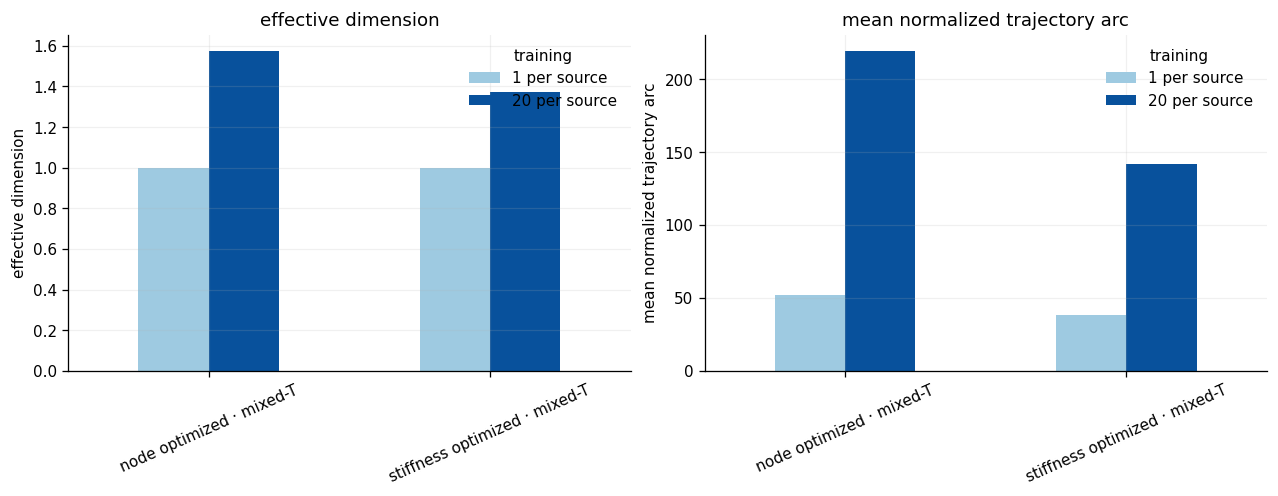

In [9]:
rich=[]
for model,item in data.items():
    frames=item['latents']
    initial=frames.query('frame==0')
    pooled_cov=np.cov(initial[['z0','z1']].to_numpy().T)
    pooled_trace=np.trace(pooled_cov)
    scale=np.sqrt(pooled_trace)
    for source in DISPLAY_SOURCES:
        g0=initial.query('source==@source')[['z0','z1']].to_numpy()
        eig=np.linalg.eigvalsh(np.cov(g0.T)).clip(min=0)
        effective=float(eig.sum()**2/(eig@eig)) if eig@eig>0 else np.nan
        relative_radius=float(np.sqrt(eig.sum()/pooled_trace))
        paths=frames.query('source==@source').sort_values(['trajectory_id','frame'])
        arc=[]
        for _,trajectory in paths.groupby('trajectory_id'):
            z=trajectory[['z0','z1']].to_numpy()/scale
            arc.append(np.linalg.norm(np.diff(z,axis=0),axis=1).sum())
        rich.append({'training':model,'source':LABELS[source],'effective dimension':effective,'relative initial radius':relative_radius,'mean normalized trajectory arc':np.mean(arc)})
richness=pd.DataFrame(rich)
display(richness.round(3))

fig,axes=plt.subplots(1,2,figsize=(11,4.2),constrained_layout=True)
for ax,metric in zip(axes,['effective dimension','mean normalized trajectory arc']):
    pivot=richness.pivot(index='source',columns='training',values=metric).loc[[LABELS[s] for s in DISPLAY_SOURCES]]
    pivot.plot.bar(ax=ax,color=['#9ecae1','#08519c'])
    ax.set(title=metric,ylabel=metric,xlabel='')
    ax.tick_params(axis='x',rotation=24)
plt.show()


## Rollout

The curve is a secondary horizon diagnostic: at every MD step, the predicted p-ratio and ground-truth p-ratio are measured at that same frame across the same 80 held-out networks. Thermal fluctuations therefore make the curve noisy. The final-step scatter is the clearer summary of the network-by-network prediction.


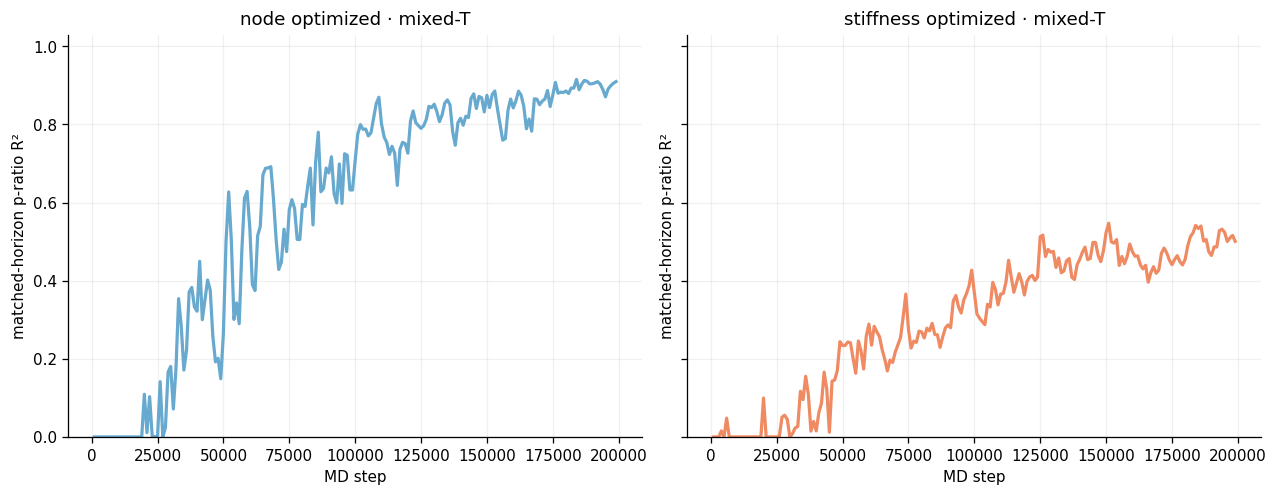

Prediction and ground truth are evaluated at the same frame. Negative R² values are shown at zero only in the plot.


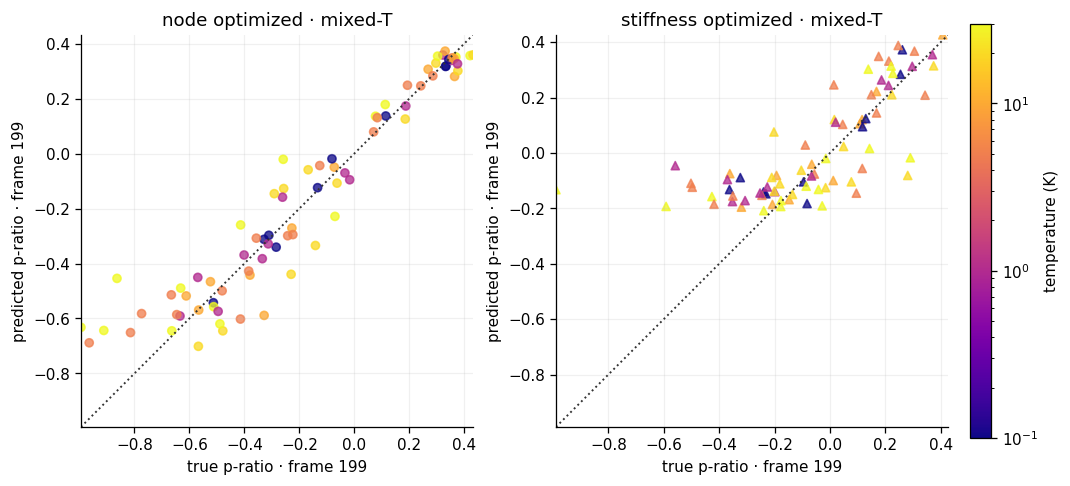

,source,frame,MD step,R²,valid/total
0,node optimized · mixed-T,199,199000,0.910,80/80
1,stiffness optimized · mixed-T,199,199000,0.501,80/80


In [10]:
item=data['20 per source']
fig,axes=plt.subplots(1,2,figsize=(11.0,4.2),sharey=True,constrained_layout=True)
for ax,source in zip(axes,DISPLAY_SOURCES):
    values=item['step'].query('source==@source and mode==@ROLLOUT_MODE and frame>0').sort_values('frame')
    ax.plot(values.frame*1000,values.p_ratio_r2.clip(lower=0),lw=2.0,color=COLORS[source])
    ax.set(title=LABELS[source],xlabel='MD step',ylabel='matched-horizon p-ratio R²',ylim=(0,1.03))
plt.show()
print('Prediction and ground truth are evaluated at the same frame. Negative R² values are shown at zero only in the plot.')

final_frame=int(item['network'].frame.max())
fig,axes=plt.subplots(1,2,figsize=(9.2,4.2),constrained_layout=True)
final_rows=[]
for ax,source in zip(axes,DISPLAY_SOURCES):
    points=(item['network'].query('source==@source and mode==@ROLLOUT_MODE and frame==@final_frame')
            .dropna(subset=['true_p_ratio','pred_p_ratio'])
            .merge(temperatures,on=['source','trajectory_id'],validate='one_to_one'))
    score=item['step'].query('source==@source and mode==@ROLLOUT_MODE and frame==@final_frame').iloc[0]
    lo=min(points.true_p_ratio.min(),points.pred_p_ratio.min()); hi=max(points.true_p_ratio.max(),points.pred_p_ratio.max())
    ax.scatter(points.true_p_ratio,points.pred_p_ratio,c=points.temperature_K,cmap=TEMP_CMAP,norm=TEMP_NORM,
               marker=MARKERS[source],s=26,alpha=.76)
    ax.plot([lo,hi],[lo,hi],ls=':',lw=1.2,color='#333333')
    ax.set(title=LABELS[source],
           xlabel=f'true p-ratio · frame {final_frame}',ylabel=f'predicted p-ratio · frame {final_frame}',xlim=(lo,hi),ylim=(lo,hi),aspect='equal')
    final_rows.append({'source':LABELS[source],'frame':final_frame,'MD step':final_frame*1000,
                       'R²':score.p_ratio_r2,'valid/total':f"{int(score.p_ratio_valid)}/{int(score.p_ratio_total)}"})
fig.colorbar(plt.cm.ScalarMappable(norm=TEMP_NORM,cmap=TEMP_CMAP),ax=axes,label='temperature (K)',fraction=.025,pad=.02)
plt.show()
display(pd.DataFrame(final_rows).round({'R²':3}))


## Mixed-T-only rollout

This separate model trained its AE and propagator only on mixed-T trajectories. The curve uses the cumulative strain fit, and the scatter compares the final fitted p-ratio on unseen networks.


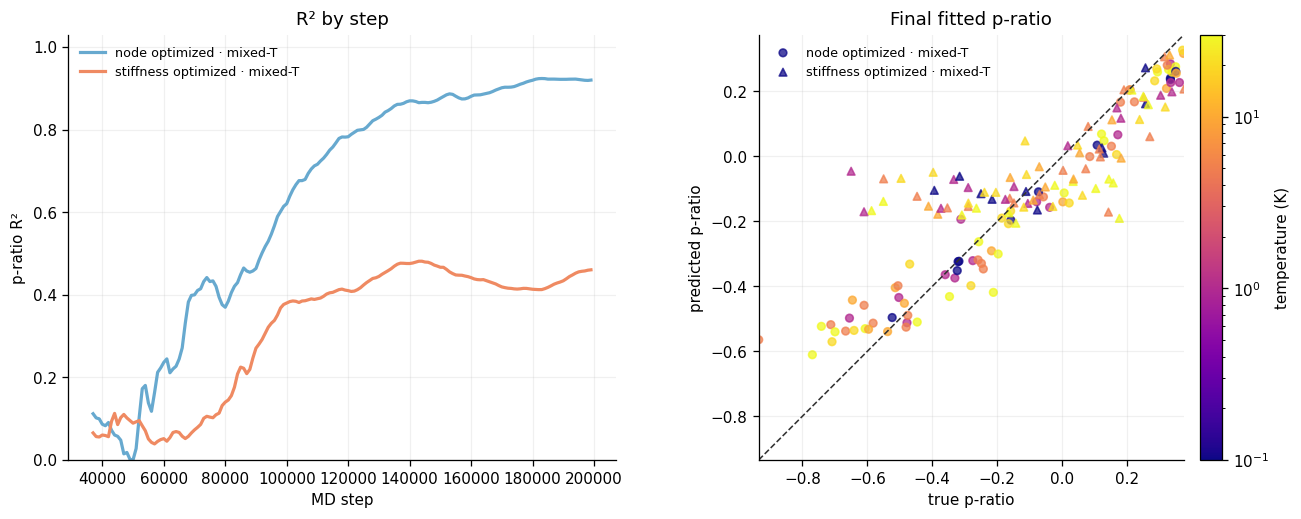

,source,p-ratio R²,p-ratio MAE,valid/total
325,node optimized · mixed-T,0.92,0.084,80/80
651,stiffness optimized · mixed-T,0.46,0.142,80/80


In [11]:
required=[MIXED_ONLY_PREFIX/'summary_prefix.csv',MIXED_ONLY_PREFIX/'completed.json',MIXED_ONLY/'linear_fit/joint_mixed_only/per_network.csv']
missing=[str(path) for path in required if not path.exists()]
if missing: raise FileNotFoundError('Mixed-T-only post-fit evaluation is not complete:\n'+'\n'.join(missing))
mixed_prefix=pd.read_csv(MIXED_ONLY_PREFIX/'summary_prefix.csv')
mixed_final=pd.read_csv(MIXED_ONLY/'linear_fit/joint_mixed_only/per_network.csv').query("mode=='autonomous_delta_mlp'")

fig,axes=plt.subplots(1,2,figsize=(11.2,4.4),constrained_layout=True)
for source in ['node_mixed','stiffness_mixed']:
    curve=mixed_prefix.query("source==@source and mode=='autonomous_delta_mlp'").sort_values('horizon')
    axes[0].plot(curve.horizon*1000,curve.linear_p_r2.clip(lower=0),lw=2,color=COLORS[source],label=LABELS[source])
    points=mixed_final.query('source==@source').merge(temperatures,on=['source','trajectory_id'],validate='one_to_one')
    axes[1].scatter(points.linear_true_p,points.linear_pred_p,c=points.temperature_K,cmap=TEMP_CMAP,norm=TEMP_NORM,
                    marker=MARKERS[source],s=23,alpha=.74,label=LABELS[source])
limits=[min(mixed_final.linear_true_p.min(),mixed_final.linear_pred_p.min()),max(mixed_final.linear_true_p.max(),mixed_final.linear_pred_p.max())]
axes[1].plot(limits,limits,'--',color='#333333',lw=1)
axes[0].set(title='R² by step',xlabel='MD step',ylabel='p-ratio R²',ylim=(0,1.03))
axes[1].set(title='Final fitted p-ratio',xlabel='true p-ratio',ylabel='predicted p-ratio',xlim=limits,ylim=limits,aspect='equal')
for ax in axes: ax.legend(fontsize=8)
fig.colorbar(plt.cm.ScalarMappable(norm=TEMP_NORM,cmap=TEMP_CMAP),ax=axes[1],label='temperature (K)',fraction=.05,pad=.03)
plt.show()

final_rows=mixed_prefix.query("mode=='autonomous_delta_mlp' and horizon==199").copy()
final_rows['source']=final_rows.source.map(LABELS)
final_rows['valid/total']=final_rows.linear_valid.astype(int).astype(str)+'/'+final_rows.linear_total.astype(int).astype(str)
display(final_rows[['source','linear_p_r2','linear_p_mae','valid/total']].rename(columns={'linear_p_r2':'p-ratio R²','linear_p_mae':'p-ratio MAE'}).round(3))


## Scope

This is one model seed, so there is no seed SD. Increasing from one to 20 trajectories per source also increases unique structures from two to 40 and broadens the mixed-temperature values; it is not a pure sample-count intervention. All 320 held-out trajectories are development-test IDs 40–119 and were not used for checkpoint selection. The comparison should be read from the source-wise initial-z correlations and response-free geometry diagnostics above, not from arbitrary axis orientation or coordinate MSE alone.
